# Project 2 — Word embeddings and sequence models

**Question:** do pretrained word vectors and word order help classify WildGuardMix prompts?

Read and run Q1–Q6 in order. Each code cell names the question it addresses.
Each section ends with an answer based on its outputs, plus what remains uncertain.
The final section compares against saved Project 1 results.

We reuse the course embedding loader, encoders, classifier, batching and training loop.
Repeated project operations are in [`utils/p2/functions.py`](../utils/p2/functions.py).
The official questions remain in [`project.ipynb`](project.ipynb).

## Setup and experiment budget

Run with the repository `.venv` kernel. The device is detected at runtime.
This notebook runs a **development pilot on fold 0**, with three epochs per model.
It is not a completed five-fold experiment. Change the settings here to experiment.
The official test is not loaded during model selection.

In [1]:
# Setup — imports, existing HF login and hardware
import json
import os
import platform
import random
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader

root = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "part2/clslib.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# Keep the normal Hugging Face login location if notebook caches are redirected.
default_hf_home = Path(os.environ.get("HF_HOME") or
                       Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache") / "huggingface")
os.environ.setdefault("HF_TOKEN_PATH", str(default_hf_home / "token"))

from datasets import load_dataset
import matplotlib.pyplot as plt
from importlib.metadata import version
from part2 import clslib, experiment
from utils.p2.functions import (
    ProjectWordTokenizer, balanced_sample, classification_scores, clean_wildguard_prompts,
    coverage_by_label, embedding_coverage, make_toy_embeddings, stratified_folds,
    nearest_words, prepare_fold, run_configuration, input_features,
)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("torch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

Python: 3.14.10
Platform: Linux-7.3.3-200.fc44.x86_64-x86_64-with-glibc2.43
torch: 2.15.0+cu132
MPS available: False
Device: cuda


In [2]:
# Setup — change these values to experiment
use_toy_data = False
seed = 42
examples_per_class = 23078
num_folds = 5
fold_index = 0
embedding_dims = 50
num_epochs = 15  # Actually used for every fit below; start with a small pilot.
batch_size = 64
hidden_size = 64
dropout = 0.2
learning_rate = 0.001
weight_decay = 0.0001
repeat_seeds = [seed, seed + 1]  # Initialization/batch-order check on the SAME data.
dataset_revision = "d29c47f41c8b51348b5c8e8c81c039b3132b66d1"
glove_path = root / "part2/glove.2024.wikigiga.50d.zip"
p1_results = root / "part1/results/project1/20261106T121706101445Z"

if use_toy_data:
    examples_per_class, num_folds, embedding_dims = 6, 3, 12
    num_epochs, batch_size, hidden_size = 2, 4, 8

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
results_folder = root / "part2/results" / ("toy" if use_toy_data else "pilot") / run_id
results_folder.mkdir(parents=True, exist_ok=False)
settings = dict(status="SMOKE_NOT_SCIENTIFIC" if use_toy_data else "DEVELOPMENT_PILOT",
                sample_seed=seed, examples_per_class=examples_per_class, num_folds=num_folds,
                fold_index=fold_index, embedding_dims=embedding_dims, epochs=num_epochs,
                batch_size=batch_size, hidden_size=hidden_size, dropout=dropout,
                learning_rate=learning_rate, weight_decay=weight_decay,
                repeat_seeds=repeat_seeds, device=device, dataset_revision=dataset_revision,
                embedding_source=str(glove_path), official_test_accessed=False,
                checkpoint_rule="last epoch; no validation checkpoint selection",
                vocabulary="pretrained rows observed in training only; other tokens map to UNK",
                tokenizer="lowercase, punctuation removed, stopwords kept, Treebank",
                packages={name: version(name) for name in
                          ["numpy", "pandas", "torch", "nltk", "datasets", "scikit-learn"]})
(results_folder / "settings.json").write_text(json.dumps(settings, indent=2))
print(settings["status"], "|", num_epochs, "epochs per fit | outputs:", results_folder)

DEVELOPMENT_PILOT | 15 epochs per fit | outputs: /home/adame/code/school/ai/nlp1/project/nlp1-student/part2/results/pilot/20261116T153406388894Z


## Q1. Is the embedding appropriate for this dataset?

**Answer with:** the text/label definition, tokenization examples, token and type coverage,
coverage by label, and frequent missing tokens.

We start with the tutorial's English GloVe 2024 Wikipedia + Gigaword **50d** table.
English general text makes it a reasonable candidate; security jargon and typos need checking.
We lowercase, remove punctuation, and keep stopwords (including negation).
The helper extends the course tokenizer with resource-free Treebank tokenization.
This is an explicit approximation to GloVe's preprocessing, not a claim of an exact match.
Removing punctuation splits contractions and changes URLs/code; inspect the examples below.

In [3]:
# Q1a — load, clean, balance and split the same task as Project 1
if use_toy_data:
    raw = pd.DataFrame([
        {"prompt": f"Please water the garden plants number {i}",
         "prompt_harm_label": "unharmful", "subcategory": "synthetic"}
        for i in range(8)
    ] + [
        {"prompt": f"Synthetic security misuse request number {i}",
         "prompt_harm_label": "harmful", "subcategory": "synthetic"}
        for i in range(8)
    ] + [
        {"prompt": "excluded example", "prompt_harm_label": "harmful",
         "subcategory": " toxic_language_hate_speech "},
        {"prompt": "duplicate safe prompt", "prompt_harm_label": "unharmful",
         "subcategory": "synthetic"},
        {"prompt": "duplicate safe prompt", "prompt_harm_label": "unharmful",
         "subcategory": "synthetic"},
        {"prompt": "contradiction", "prompt_harm_label": "harmful",
         "subcategory": "synthetic"},
        {"prompt": "contradiction", "prompt_harm_label": "unharmful",
         "subcategory": "synthetic"},
    ])
else:
    dataset = load_dataset(
        "allenai/wildguardmix", "wildguardtrain", split="train",
        revision=dataset_revision, token=True,
        cache_dir=str(root / ".cache/huggingface/datasets"),
    )
    assert dataset.cache_files and all(
        dataset_revision in Path(item["filename"]).parts for item in dataset.cache_files
    ), "Cached revision differs from the requested revision."
    raw = dataset.select_columns(
        ["prompt", "prompt_harm_label", "subcategory"]).to_pandas()

data, data_audit = clean_wildguard_prompts(raw)
display(pd.Series(data_audit, name="data audit"))

if not use_toy_data:
    expected = {"original_rows": 86759, "excluded_category_rows": 3020,
                "eligible_rows": 83739, "retained_rows": 46692}
    assert all(data_audit[key] == value for key, value in expected.items())

sample = balanced_sample(data, examples_per_class, seed)
folds = stratified_folds(sample["label"], num_folds, seed)
train_indices, validation_indices = folds[fold_index]
train = sample.iloc[train_indices].reset_index(drop=True)
validation = sample.iloc[validation_indices].reset_index(drop=True)
print("First fold:", len(train), "training /", len(validation), "validation")
assert set(train.id).isdisjoint(validation.id)
split_table = sample[["id", "label"]].copy()
split_table["fold"] = -1
for fold, (_, indices) in enumerate(folds):
    split_table.loc[indices, "fold"] = fold
split_table.to_csv(results_folder / "folds.csv", index=False)
(results_folder / "data_audit.json").write_text(json.dumps(data_audit, indent=2))

original_rows                  86759.00000
excluded_category_rows          3020.00000
missing_label_rows                 0.00000
eligible_rows                  83739.00000
empty_prompt_rows                 14.00000
contradictory_label_rows          30.00000
contradictory_label_groups        15.00000
duplicate_rows                 37003.00000
retained_rows                  46692.00000
retained_unharmful             23078.00000
retained_harmful               23614.00000
retained_harmful_prevalence        0.50574
Name: data audit, dtype: float64

First fold: 36924 training / 9232 validation


378

In [4]:
# Q1b — load local vectors and inspect tokenization
if use_toy_data:
    embeddings = make_toy_embeddings(
        ["please", "water", "the", "garden", "plants", "synthetic", "security", "request",
         "number", "safe", "prompt", "dog", "bites", "man"], embedding_dims, seed)
else:
    if not glove_path.exists():
        raise FileNotFoundError(f"Local GloVe archive required: {glove_path}")
    embeddings = clslib.PretrainedEmbeddings(str(glove_path), num_dims=embedding_dims)
tokenizer = ProjectWordTokenizer(lowercase=True, remove_punct=True, remove_stopwords=False,
                                 vocab=embeddings.vocab)
examples = ["Don't share your MFA code.", "Explain authentication and phishing.",
            "Please help with my gardenn."]  # Safe examples, not dataset prompts.
display(pd.DataFrame({"text": examples, "tokens": [tokenizer.tokens(s) for s in examples]}))
print("Full embedding matrix:", embeddings.vectors.shape)
print("Vector array MiB:", round(embeddings.vectors.nbytes / 2**20, 1))

,text,tokens
0,Don't share your MFA code.,"[don, t, share, your, mfa, code]"
1,Explain authentication and phishing.,"[explain, authentication, and, phishing]"
2,Please help with my gardenn.,"[please, help, with, my, gardenn]"


Full embedding matrix: (1287615, 50)
Vector array MiB: 245.6


In [5]:
# Q1c — training coverage, label-specific coverage, and OOV counts
coverage, oov = embedding_coverage(train.prompt, tokenizer, embeddings.vocab)
label_coverage = coverage_by_label(train, tokenizer, embeddings.vocab)
display(coverage)
display(label_coverage.round(4))
display(oov.head(15))
coverage.to_csv(results_folder / "embedding_coverage.csv")
label_coverage.to_csv(results_folder / "coverage_by_label.csv", index=False)
oov.to_csv(results_folder / "oov_counts.csv", index=False)
print(f"Q1 answer: the table covers {coverage.token_coverage:.2%} of token occurrences "
      f"and {coverage.type_coverage:.2%} of distinct training tokens.")
print("Frequent-token coverage and rare-word coverage differ; coverage alone does not establish classification quality.")

documents         3.692400e+04
tokens            3.139962e+06
types             4.598100e+04
token_coverage    9.946095e-01
type_coverage     8.024836e-01
Name: embedding coverage, dtype: float64

,label,documents,tokens,types,token_coverage,type_coverage
0,0,18462.0,1465683.0,36422.0,0.9923,0.8111
1,1,18462.0,1674279.0,28201.0,0.9966,0.9154


,token,frequency
0,name_1,975
1,name_2,447
2,_1,227
3,name_3,104
4,_2,99
5,littlegpt,75
6,targetlanguage,67
7,betterdan,65
8,ninclude,61
9,4w5,51


Q1 answer: the table covers 99.46% of token occurrences and 80.25% of distinct training tokens.
Frequent-token coverage and rare-word coverage differ; coverage alone does not establish classification quality.


## Q2. What does the embedding capture, and where does it fail?

**Answer with:** real neighbours for task vocabulary, an order-swap example,
and a controlled classification ablation in Q3.

GloVe assigns one vector per word, so it cannot give different representations to
different senses of the same word. Topic similarity can bring safe and unsafe requests
close together. Missing words collapse into one `<unk>` vector. Mean/sum pooling also
discards word order. These limitations matter when intent depends on context or negation.

In [6]:
# Q2a — actual nearest neighbours; no invented similarities for missing words
probe_words = ["phishing", "fraud", "authentication", "mfa", "garden"]
display(pd.DataFrame({"word": probe_words, "in_vocabulary": [w in embeddings.vocab for w in probe_words]}))
neighbours = pd.concat([nearest_words(embeddings, word) for word in probe_words], ignore_index=True)
display(neighbours.round(4))
neighbours.to_csv(results_folder / "embedding_neighbours.csv", index=False)
print("These are distributional associations; inspect whether they express topic, syntax, or intent.")

,word,in_vocabulary
0,phishing,True
1,fraud,True
2,authentication,True
3,mfa,True
4,garden,True


,query,neighbour,cosine
0,phishing,scams,0.7580
1,phishing,scammers,0.7212
2,phishing,malware,0.7075
3,phishing,malicious,0.6956
4,phishing,astroturfing,0.6867
5,fraud,charges,0.8763
6,fraud,bribery,0.8589
7,fraud,alleged,0.8540
8,fraud,embezzlement,0.8407
9,fraud,alleging,0.8379


These are distributional associations; inspect whether they express topic, syntax, or intent.


In [7]:
# Q2b — a concrete limitation: pooled vectors lose word order
sentences = ["dog bites man", "man bites dog"]
vectors = [np.mean([embeddings.embed_word(t) for t in tokenizer.tokens(s)], axis=0)
           for s in sentences]
distance = float(np.linalg.norm(vectors[0] - vectors[1]))
print("Mean-vector distance for the order swap:", distance)
assert np.allclose(vectors[0], vectors[1], atol=1e-6)
print("Q2 answer: the same words produce the same pooled vector, although the roles changed.")
print("Task-specific evidence for pretraining comes from Q3's trainable GloVe vs trainable random comparison.")
print("We have not compared another pretrained family or embedding dimension.")

Mean-vector distance for the order swap: 3.3618550787650747e-07
Q2 answer: the same words produce the same pooled vector, although the roles changed.
Task-specific evidence for pretraining comes from Q3's trainable GloVe vs trainable random comparison.
We have not compared another pretrained family or embedding dimension.


## Q3. Which embed-and-pool choices matter?

**Answer with:** mean vs sum pooling, frozen vs trainable GloVe, and trainable
GloVe vs trainable random vectors. The last pair holds architecture, vocabulary,
trainability and budget fixed to examine initialization. A single pilot cannot prove an advantage.

For affordable fine-tuning, every model uses the **same training-only vocabulary**
of words found in the pretrained table. Validation-only words map to `<unk>`.
This restriction differs from using the entire GloVe table; we report its effect below.
We use the course classifier (two tanh layers), AdamW and a fixed epoch budget.
The setting `num_epochs` controls the training loop. The final epoch is scored.

In [8]:
# Q3a — prepare shared inputs and explicit configurations
prepared = prepare_fold(train, validation, embeddings, tokenizer)
restricted_coverage, _ = embedding_coverage(validation.prompt, tokenizer, prepared["vocab"])
full_validation_coverage, _ = embedding_coverage(validation.prompt, tokenizer, embeddings.vocab)
display(pd.DataFrame({"full pretrained table": full_validation_coverage,
                      "training-only model vocabulary": restricted_coverage}))
print("Compact matrix:", prepared["vectors"].shape, "| same IDs for every configuration")
common = dict(hidden_size=hidden_size, classifier_width=hidden_size, dropout=dropout)
pool_configs = [
    dict(name="mean_frozen", encoder="mean", initialization="pretrained", frozen=True, **common),
    dict(name="sum_frozen", encoder="sum", initialization="pretrained", frozen=True, **common),
    dict(name="mean_tuned", encoder="mean", initialization="pretrained", frozen=False, **common),
    dict(name="mean_random", encoder="mean", initialization="random", frozen=False, **common),
]
fit_options = dict(epochs=num_epochs, batch_size=batch_size, learning_rate=learning_rate,
                   weight_decay=weight_decay, device=device)
score_rows, histories, prediction_tables = [], [], []

,full pretrained table,training-only model vocabulary
documents,9232.000000,9232.000000
tokens,782114.000000,782114.000000
types,24665.000000,24665.000000
token_coverage,0.993537,0.987782
type_coverage,0.877965,0.758889


Compact matrix: (36901, 50) | same IDs for every configuration


In [9]:
# Q3b — run the four pooling comparisons on the same fold
for config in pool_configs:
    score, history, predictions = run_configuration(prepared, config, seed=seed, **fit_options)
    score_rows.append(score)
    histories.append(history)
    prediction_tables.append(predictions)
pool_results = pd.DataFrame(score_rows).set_index("name")
display(pool_results[["macro_f1", "harmful_recall", "benign_fpr", "trainable_parameters", "fit_seconds"]].round(4))
for a, b, question in [("mean_frozen", "sum_frozen", "sum versus mean"),
                       ("mean_frozen", "mean_tuned", "fine-tuning GloVe"),
                       ("mean_random", "mean_tuned", "pretraining at equal trainability")]:
    delta = pool_results.loc[b, "macro_f1"] - pool_results.loc[a, "macro_f1"]
    print(f"Q3 observed difference ({question}): {delta:+.4f} macro-F1 (B - A).")
print("See the final table for P1; these pilot differences are not yet stable estimates.")

mean_frozen | seed 42 | epoch 1/15 | validation F1 0.7229
mean_frozen | seed 42 | epoch 2/15 | validation F1 0.7071
mean_frozen | seed 42 | epoch 3/15 | validation F1 0.7152
mean_frozen | seed 42 | epoch 4/15 | validation F1 0.7229
mean_frozen | seed 42 | epoch 5/15 | validation F1 0.7282
mean_frozen | seed 42 | epoch 6/15 | validation F1 0.7019
mean_frozen | seed 42 | epoch 7/15 | validation F1 0.7312
mean_frozen | seed 42 | epoch 8/15 | validation F1 0.7256
mean_frozen | seed 42 | epoch 9/15 | validation F1 0.7252
mean_frozen | seed 42 | epoch 10/15 | validation F1 0.7240
mean_frozen | seed 42 | epoch 11/15 | validation F1 0.7200
mean_frozen | seed 42 | epoch 12/15 | validation F1 0.7192
mean_frozen | seed 42 | epoch 13/15 | validation F1 0.7307
mean_frozen | seed 42 | epoch 14/15 | validation F1 0.7355
mean_frozen | seed 42 | epoch 15/15 | validation F1 0.7330
sum_frozen | seed 42 | epoch 1/15 | validation F1 0.7331
sum_frozen | seed 42 | epoch 2/15 | validation F1 0.6926
sum_frozen

,macro_f1,harmful_recall,benign_fpr,trainable_parameters,fit_seconds
name,,,,,
mean_frozen,0.7330,0.7541,0.2879,7554,20.0574
sum_frozen,0.7459,0.8358,0.3401,7554,19.4386
mean_tuned,0.8544,0.8655,0.1566,1852604,22.7602
mean_random,0.8451,0.8477,0.1575,1852604,22.9077


Q3 observed difference (sum versus mean): +0.0129 macro-F1 (B - A).
Q3 observed difference (fine-tuning GloVe): +0.1214 macro-F1 (B - A).
Q3 observed difference (pretraining at equal trainability): +0.0093 macro-F1 (B - A).
See the final table for P1; these pilot differences are not yet stable estimates.


## Q4. Does a recurrent encoder help?

**Answer with:** LSTM vs mean pooling, frozen vs trainable embeddings, half vs full
training data, and a dropout change. We keep validation fixed for the size comparison
and use a nested balanced subset of training examples. Its vocabulary stays fixed to
isolate the amount of labelled training data.

Loss curves show optimization and possible overfitting. Rising validation loss while
training loss falls is a warning, not a cause diagnosis. This short budget does not
establish the best performance an LSTM can reach. An inner development split would
be needed for early stopping without selecting on the reported evaluation fold.

In [10]:
# Q4a — recurrent architecture, trainability, data size and dropout
lstm_configs = [
    dict(name="lstm_frozen", encoder="lstm", initialization="pretrained", frozen=True, **common),
    dict(name="lstm_tuned", encoder="lstm", initialization="pretrained", frozen=False, **common),
    dict(name="lstm_half_data", encoder="lstm", initialization="pretrained", frozen=True, **common),
    dict(name="lstm_dropout", encoder="lstm", initialization="pretrained", frozen=True,
         **{**common, "dropout": 0.4}),
]
small_train = balanced_sample(train, max(1, len(train) // 4), seed)
positions = pd.Index(train.id).get_indexer(small_train.id)
small_prepared = {**prepared, "train": small_train,
                  "train_ids": [prepared["train_ids"][i] for i in positions]}
for config in lstm_configs:
    inputs = small_prepared if config["name"] == "lstm_half_data" else prepared
    score, history, predictions = run_configuration(inputs, config, seed=seed, **fit_options)
    score_rows.append(score)
    histories.append(history)
    prediction_tables.append(predictions)
all_results = pd.DataFrame(score_rows).set_index("name")
display(all_results.loc[["mean_frozen"] + [c["name"] for c in lstm_configs],
                        ["n_train", "macro_f1", "harmful_recall", "benign_fpr", "trainable_parameters"]].round(4))
for a, b in [("mean_frozen", "lstm_frozen"), ("lstm_frozen", "lstm_tuned"),
              ("lstm_half_data", "lstm_frozen"), ("lstm_frozen", "lstm_dropout")]:
    print(f"Q4: {b} minus {a}: {all_results.loc[b, 'macro_f1'] - all_results.loc[a, 'macro_f1']:+.4f} macro-F1.")

lstm_frozen | seed 42 | epoch 1/15 | validation F1 0.7206
lstm_frozen | seed 42 | epoch 2/15 | validation F1 0.7786
lstm_frozen | seed 42 | epoch 3/15 | validation F1 0.7565
lstm_frozen | seed 42 | epoch 4/15 | validation F1 0.8127
lstm_frozen | seed 42 | epoch 5/15 | validation F1 0.8152
lstm_frozen | seed 42 | epoch 6/15 | validation F1 0.8224
lstm_frozen | seed 42 | epoch 7/15 | validation F1 0.8252
lstm_frozen | seed 42 | epoch 8/15 | validation F1 0.8247
lstm_frozen | seed 42 | epoch 9/15 | validation F1 0.8372
lstm_frozen | seed 42 | epoch 10/15 | validation F1 0.8335
lstm_frozen | seed 42 | epoch 11/15 | validation F1 0.8315
lstm_frozen | seed 42 | epoch 12/15 | validation F1 0.8404
lstm_frozen | seed 42 | epoch 13/15 | validation F1 0.8363
lstm_frozen | seed 42 | epoch 14/15 | validation F1 0.8385
lstm_frozen | seed 42 | epoch 15/15 | validation F1 0.8407
lstm_tuned | seed 42 | epoch 1/15 | validation F1 0.7978
lstm_tuned | seed 42 | epoch 2/15 | validation F1 0.8159
lstm_tuned

,n_train,macro_f1,harmful_recall,benign_fpr,trainable_parameters
name,,,,,
mean_frozen,36924,0.7330,0.7541,0.2879,7554
lstm_frozen,36924,0.8407,0.8399,0.1586,38146
lstm_tuned,36924,0.8474,0.8741,0.1792,1883196
lstm_half_data,18462,0.8214,0.7426,0.0975,38146
lstm_dropout,36924,0.8391,0.8089,0.1304,38146


Q4: lstm_frozen minus mean_frozen: +0.1077 macro-F1.
Q4: lstm_tuned minus lstm_frozen: +0.0067 macro-F1.
Q4: lstm_frozen minus lstm_half_data: +0.0192 macro-F1.
Q4: lstm_dropout minus lstm_frozen: -0.0016 macro-F1.


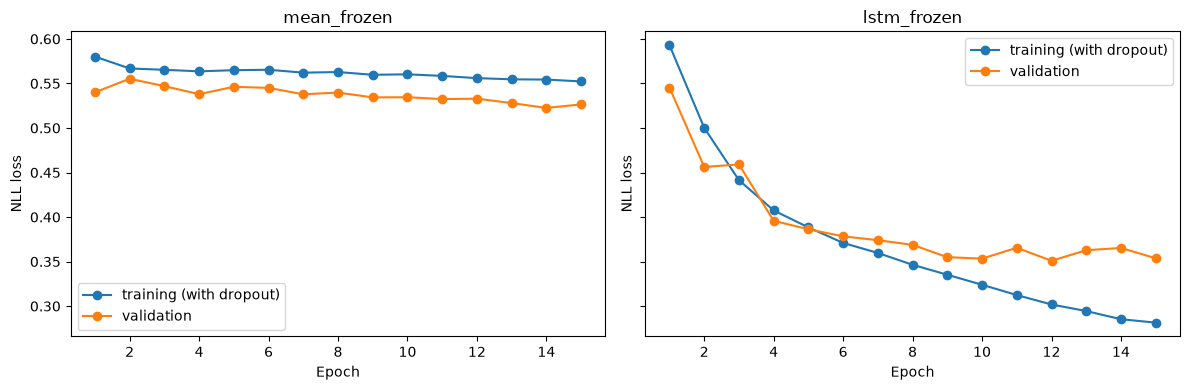

lstm_dropout : 4 epoch transitions with falling train / rising validation loss
lstm_frozen : 4 epoch transitions with falling train / rising validation loss
lstm_half_data : 5 epoch transitions with falling train / rising validation loss
lstm_tuned : 9 epoch transitions with falling train / rising validation loss
mean_frozen : 3 epoch transitions with falling train / rising validation loss
mean_random : 9 epoch transitions with falling train / rising validation loss
mean_tuned : 9 epoch transitions with falling train / rising validation loss
sum_frozen : 4 epoch transitions with falling train / rising validation loss
Q4 limit: training loss uses dropout and changing parameters; the curves are a diagnostic.


In [11]:
# Q4b — inspect training and validation loss over epochs
history_table = pd.concat(histories, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, system in zip(axes, ["mean_frozen", "lstm_frozen"]):
    curve = history_table[history_table.system == system]
    ax.plot(curve.epoch, curve.train_loss, marker="o", label="training (with dropout)")
    ax.plot(curve.epoch, curve.validation_loss, marker="o", label="validation")
    ax.set(title=system, xlabel="Epoch", ylabel="NLL loss")
    ax.legend()
fig.tight_layout()
fig.savefig(results_folder / "learning_curves.png", dpi=150)
plt.show()
for system, curve in history_table.groupby("system"):
    curve = curve.sort_values("epoch")
    warning = ((curve.train_loss.diff() < 0) & (curve.validation_loss.diff() > 0)).sum()
    print(system, ":", int(warning), "epoch transitions with falling train / rising validation loss")
print("Q4 limit: training loss uses dropout and changing parameters; the curves are a diagnostic.")

## Q5. How much evidence supports our choices?

**Search plan:** eight motivated configurations, changing one factor at a time within
each contrast. Then repeat two prespecified systems with new training seeds.
The sample and fold are fixed: this measures initialization/batch-order variation,
not dataset or fold variation. Two seeds are a small diagnostic, not a robust ranking.

After this pilot, choose a shortlist, lock settings and evaluate shared folds/seeds.
Report paired differences and descriptive spread. Do not divide a fold SD by the
square root of the number of folds as though they were independent measurements.
Do not select models on the official test.

In [12]:
# Q5a — repeat fixed baseline systems; do not choose repeats from the winning score
repeat_configs = [pool_configs[0], lstm_configs[0]]
for model_seed in repeat_seeds[1:]:
    for config in repeat_configs:
        score, history, predictions = run_configuration(prepared, config, seed=model_seed, **fit_options)
        score_rows.append(score)
        histories.append(history)
        prediction_tables.append(predictions)
scores = pd.DataFrame(score_rows)
history_table = pd.concat(histories, ignore_index=True)
predictions = pd.concat(prediction_tables, ignore_index=True)
scores["fold"] = fold_index
predictions["fold"] = fold_index
variance = scores[scores.name.isin(["mean_frozen", "lstm_frozen"])].groupby("name").agg(
    mean_f1=("macro_f1", "mean"), seed_sd=("macro_f1", "std"), runs=("seed", "nunique"))
display(variance.round(4))
paired = scores[scores.name.isin(["mean_frozen", "lstm_frozen"])].pivot(
    index="seed", columns="name", values="macro_f1")
paired["lstm_minus_pool"] = paired.lstm_frozen - paired.mean_frozen
display(paired.round(4))
print("Q5 answer: this measures training-seed variation on one fixed fold only.")
print("Further evaluation needs multiple held-out folds; a consistent pilot sign alone does not establish superiority.")

mean_frozen | seed 43 | epoch 1/15 | validation F1 0.7079
mean_frozen | seed 43 | epoch 2/15 | validation F1 0.7161
mean_frozen | seed 43 | epoch 3/15 | validation F1 0.7268
mean_frozen | seed 43 | epoch 4/15 | validation F1 0.7267
mean_frozen | seed 43 | epoch 5/15 | validation F1 0.7266
mean_frozen | seed 43 | epoch 6/15 | validation F1 0.7278
mean_frozen | seed 43 | epoch 7/15 | validation F1 0.7232
mean_frozen | seed 43 | epoch 8/15 | validation F1 0.7282
mean_frozen | seed 43 | epoch 9/15 | validation F1 0.7168
mean_frozen | seed 43 | epoch 10/15 | validation F1 0.7229
mean_frozen | seed 43 | epoch 11/15 | validation F1 0.7225
mean_frozen | seed 43 | epoch 12/15 | validation F1 0.7318
mean_frozen | seed 43 | epoch 13/15 | validation F1 0.7291
mean_frozen | seed 43 | epoch 14/15 | validation F1 0.7256
mean_frozen | seed 43 | epoch 15/15 | validation F1 0.7320
lstm_frozen | seed 43 | epoch 1/15 | validation F1 0.7113
lstm_frozen | seed 43 | epoch 2/15 | validation F1 0.7676
lstm_fro

,mean_f1,seed_sd,runs
name,,,
lstm_frozen,0.8426,0.0028,2
mean_frozen,0.7325,0.0007,2


name,lstm_frozen,mean_frozen,lstm_minus_pool
seed,,,
42,0.8407,0.733,0.1077
43,0.8446,0.732,0.1126


Q5 answer: this measures training-seed variation on one fixed fold only.
Further evaluation needs multiple held-out folds; a consistent pilot sign alone does not establish superiority.


## Q6. Which text characteristics accompany errors?

**Features chosen before inspecting these results:** token length, OOV fraction,
negation and security terms. We now join these to held-out correctness and confidence
for each system. Error rates and counts by feature bin make the analysis testable.
These predictions come from a development fold used for comparisons, not an untouched test.
We show IDs rather than raw dataset prompts.

In [17]:
# Q6a — join input features to actual held-out predictions
features = pd.DataFrame([input_features(text, tokenizer, prepared["vocab"])
                         for text in validation.prompt])
features["id"] = validation.id.to_numpy()
features["length_bin"] = pd.cut(features.token_length, [-1, 32, 128, np.inf],
                                  labels=["0–32", "33–128", "129+"])
features["oov_bin"] = pd.cut(features.oov_fraction, [-1, 0, 0.05, 1],
                               labels=["none", "0–5%", ">5%"])
errors = predictions[predictions.seed == seed].merge(features, on="id", validate="many_to_one")
errors["wrong"] = errors.gold != errors.prediction
errors["confidently_wrong"] = errors.wrong & errors.confidence.ge(0.8)
errors["false_negative"] = errors.gold.eq(1) & errors.prediction.eq(0)
errors["false_positive"] = errors.gold.eq(0) & errors.prediction.eq(1)
error_bins = []
major = errors[errors.system.isin(["mean_frozen", "lstm_frozen"])]
for feature in ["length_bin", "oov_bin", "has_negation", "has_security_term"]:
    table = major.groupby(["system", feature], observed=True).agg(
        n=("wrong", "size"), error_rate=("wrong", "mean"),
        harmful_share=("gold", "mean"), confidently_wrong=("confidently_wrong", "sum")).reset_index()
    table = table.rename(columns={feature: "bin"}).assign(feature=feature)
    error_bins.append(table)
    print(feature)
    display(table.round(4))
error_bins = pd.concat(error_bins, ignore_index=True)
display(major[major.wrong].sort_values("confidence", ascending=False)[
    ["system", "id", "gold", "prediction", "confidence", "token_length", "oov_fraction"]].head(10))
print("Q6 answer: the tables test the proposed associations, with group counts and class mix.")
print("Priorities: inspect enough errors in high-error groups, check negation/order and rare terms, then validate targeted changes on fresh folds.")
print("Small groups, correlated features and uncalibrated confidence limit interpretation; these are not causal effects.")

length_bin


,system,bin,n,error_rate,harmful_share,confidently_wrong,feature
0,lstm_frozen,0–32,4316,0.0818,0.4875,186,length_bin
1,lstm_frozen,33–128,2544,0.2127,0.4650,167,length_bin
2,lstm_frozen,129+,2372,0.2433,0.5603,182,length_bin
3,mean_frozen,0–32,4316,0.1911,0.4875,134,length_bin
4,mean_frozen,33–128,2544,0.3180,0.4650,18,length_bin
5,mean_frozen,129+,2372,0.3499,0.5603,8,length_bin


oov_bin


,system,bin,n,error_rate,harmful_share,confidently_wrong,feature
0,lstm_frozen,none,6956,0.1429,0.5109,371,oov_bin
1,lstm_frozen,0–5%,1714,0.2287,0.5117,126,oov_bin
2,lstm_frozen,>5%,562,0.1512,0.3292,38,oov_bin
3,mean_frozen,none,6956,0.2510,0.5109,123,oov_bin
4,mean_frozen,0–5%,1714,0.3291,0.5117,12,oov_bin
5,mean_frozen,>5%,562,0.2740,0.3292,25,oov_bin


has_negation


,system,bin,n,error_rate,harmful_share,confidently_wrong,feature
0,lstm_frozen,False,6273,0.1286,0.5029,332,has_negation
1,lstm_frozen,True,2959,0.2244,0.4937,203,has_negation
2,mean_frozen,False,6273,0.2337,0.5029,147,has_negation
3,mean_frozen,True,2959,0.3373,0.4937,13,has_negation


has_security_term


,system,bin,n,error_rate,harmful_share,confidently_wrong,feature
0,lstm_frozen,False,8950,0.1596,0.4907,522,has_security_term
1,lstm_frozen,True,282,0.1525,0.7943,13,has_security_term
2,mean_frozen,False,8950,0.2678,0.4907,155,has_security_term
3,mean_frozen,True,282,0.2376,0.7943,5,has_security_term


,system,id,gold,prediction,confidence,token_length,oov_fraction
39262,lstm_frozen,wg-d723046a9411d70f030631d578461a299a2f25db457...,0,1,0.996484,18,0.222222
43936,lstm_frozen,wg-37b72b9cfd68b7f71c3c28c305c09b6abbd2dfa4ed9...,0,1,0.996440,78,0.064103
38314,lstm_frozen,wg-937876ea906735b28aa7d98c4ddecf7896414378516...,0,1,0.995959,37,0.000000
45781,lstm_frozen,wg-3e036e75a333621688e9143aea415376b4c579355f4...,1,0,0.995548,11,0.000000
41767,lstm_frozen,wg-ada57c466826a744bcbf7d0a07bb5fcde2702925d04...,0,1,0.994506,15,0.000000
37006,lstm_frozen,wg-c37017651367207235a84497fa7598b0166341ea537...,0,1,0.994185,13,0.000000
39293,lstm_frozen,wg-33a264d972c57e2e88a22eebb01d88803098383f138...,0,1,0.992857,101,0.000000
41312,lstm_frozen,wg-a7ca4f4a32f1905fe85565f1493439d274f0320c9d2...,1,0,0.991684,9,0.111111
37053,lstm_frozen,wg-d2760ae1009bc63123ab7a11ef3751ba1f6ec5d44c1...,0,1,0.990577,15,0.000000
44511,lstm_frozen,wg-e955b8a1a10a657e72ded69a5f9080a6c9f07d775dc...,1,0,0.990271,9,0.111111


Q6 answer: the tables test the proposed associations, with group counts and class mix.
Priorities: inspect enough errors in high-error groups, check negation/order and rare terms, then validate targeted changes on fresh folds.
Small groups, correlated features and uncalibrated confidence limit interpretation; these are not causal effects.


## Final comparison — Project 2 versus Project 1

The first table is a **historical reference**: P1's repeated CV and official-test
results remain separate. P2 has no final test score yet.

The second comparison uses P1's exact same sample and fold, checked using every
hashed ID and label. P1 neural models used ten epochs; P2 uses the budget above.
Different tokenization, optimization and software versions also matter. Even with
the same split, this comparison cannot isolate pretraining by itself; Q3's matched
trainable initialization ablation is the relevant evidence for that question.

In [23]:
# Final comparison A — read real saved P1 metrics, with their protocol
p1_results = root / "part1/results/project1/20261116T155245339311Z"
p1_available = (p1_results / "p1_cv_scores.csv").exists() and not use_toy_data
if p1_available:
    p1_settings = json.loads((p1_results / "settings.json").read_text())
    p1_summary = pd.read_csv(p1_results / "p1_summary.csv")
    p1_summary["system"] = p1_summary.model + "/" + p1_summary.representation
    p1_reference = p1_summary[["system", "macro_f1_mean", "macro_f1_std"]].copy()
    p1_reference["protocol"] = f"{p1_settings['runs']} samples × {p1_settings['folds']} folds; {p1_settings['epochs']} MLP epochs"
    test_path = p1_results / "p1_test_summary.csv"
    if test_path.exists():
        p1_reference = p1_reference.merge(pd.read_csv(test_path)[["system", "test_macro_f1"]], on="system")
    display(p1_reference.round(4))
    p1_reference.to_csv(results_folder / "p1_historical_reference.csv", index=False)
    print("P1 source:", p1_results)
else:
    print("P1 saved metrics unavailable or toy mode active; no historical scores invented.")

,system,macro_f1_mean,macro_f1_std,protocol,test_macro_f1
0,logistic/bow,0.7807,0.0121,5 samples × 5 folds; 10 MLP epochs,0.7341
1,logistic/indicators,0.7842,0.0109,5 samples × 5 folds; 10 MLP epochs,0.7389
2,logistic/tfidf,0.8024,0.0101,5 samples × 5 folds; 10 MLP epochs,0.7601
3,mlp1/bow,0.8037,0.0090,5 samples × 5 folds; 10 MLP epochs,0.7585
4,mlp1/indicators,0.8006,0.0102,5 samples × 5 folds; 10 MLP epochs,0.7597
5,mlp1/tfidf,0.7948,0.0106,5 samples × 5 folds; 10 MLP epochs,0.7511
6,mlp2/bow,0.8015,0.0128,5 samples × 5 folds; 10 MLP epochs,0.7547
7,mlp2/indicators,0.7991,0.0094,5 samples × 5 folds; 10 MLP epochs,0.7494
8,mlp2/tfidf,0.7882,0.0120,5 samples × 5 folds; 10 MLP epochs,0.7465


P1 source: /home/adame/code/school/ai/nlp1/project/nlp1-student/part1/results/project1/20261116T155245339311Z


In [24]:
# Final comparison B — verify sample/fold identity before comparing scores
if p1_available:
    assert p1_settings["dataset_revision"] == dataset_revision
    assert p1_settings["examples_per_class"] == examples_per_class
    assert p1_settings["folds"] == num_folds
    p1_run = p1_settings["sample_seeds"].index(seed)
    p1_folds = pd.read_csv(p1_results / "folds.csv")
    saved = p1_folds[p1_folds.run == p1_run].set_index("id")[["gold", "fold"]].sort_index()
    current = split_table.rename(columns={"label": "gold"}).set_index("id")[["gold", "fold"]].sort_index()
    pd.testing.assert_frame_equal(saved, current, check_dtype=False)
    p1_cv = pd.read_csv(p1_results / "p1_cv_scores.csv")
    p1_matched = p1_cv[(p1_cv.run == p1_run) & (p1_cv.fold == fold_index)].copy()
    p1_matched["system"] = "P1 / " + p1_matched.model + " / " + p1_matched.representation
    p1_matched["budget"] = p1_matched.model.map(
        lambda m: "solver convergence" if m == "logistic" else f"{p1_settings['epochs']} epochs")
    p2_matched = scores[scores.seed == seed].copy()
    p2_matched["system"] = "P2 / " + p2_matched.name
    p2_matched["budget"] = p2_matched.epochs.astype(str) + " epochs"
    p1_matched["n_train"] = len(split_table) - len(saved[saved.fold == fold_index])
    columns = ["system", "n_train", "budget", "macro_f1", "harmful_recall", "benign_fpr"]
    comparison = pd.concat([p1_matched[columns], p2_matched[columns]], ignore_index=True)
    display(comparison.round(4))
    comparison.to_csv(results_folder / "p1_p2_same_fold.csv", index=False)
    for p1_name in ["logistic/tfidf", "mlp1/bow"]:
        model, representation = p1_name.split("/")
        reference = p1_matched[(p1_matched.model == model) & (p1_matched.representation == representation)].macro_f1.iloc[0]
        for p2_name in ["mean_frozen", "mean_tuned", "lstm_frozen", "lstm_tuned"]:
            value = p2_matched[p2_matched.name == p2_name].macro_f1.iloc[0]
            print(f"Same-fold pilot: {p2_name} minus P1 {p1_name}: {value - reference:+.4f} macro-F1.")
    print("Conclusion scope: observed differences on one development fold, with unequal budgets; no final claim that P2 is better.")

AssertionError: 

In [20]:
# Save — evidence for the blog, with no raw prompt text
scores.to_csv(results_folder / "p2_scores.csv", index=False)
history_table.to_csv(results_folder / "p2_training_history.csv", index=False)
predictions.to_csv(results_folder / "p2_validation_predictions.csv", index=False)
features.to_csv(results_folder / "p2_input_features.csv", index=False)
error_bins.to_csv(results_folder / "p2_error_bins.csv", index=False)
variance.to_csv(results_folder / "p2_seed_variance.csv")
paired.to_csv(results_folder / "p2_paired_differences.csv")
settings["configurations"] = pool_configs + lstm_configs
settings["p1_reference"] = str(p1_results) if p1_available else None
settings["completed_fits"] = len(scores)
(results_folder / "settings.json").write_text(json.dumps(settings, indent=2))
print("Saved", len(scores), "fits and their evidence to", results_folder)
print("Next research step: freeze a shortlist and evaluate paired folds; keep the official test for final evaluation.")

Saved 10 fits and their evidence to /home/adame/code/school/ai/nlp1/project/nlp1-student/part2/results/pilot/20261116T153406388894Z
Next research step: freeze a shortlist and evaluate paired folds; keep the official test for final evaluation.
